# 📑 Table of Contents

| # | Section | # | Section |
|---|---------|---|---------|
| 1 | 🎨 [Cover Page](#-Sales-Prediction-using-Python) | 12 | 🏆 [Model Comparison](#-12.-Model-Comparison) |
| 2 | 📑 [Table of Contents](#-Table-of-Contents) | 13 | 🌟 [Feature Importance](#-13.-Feature-Importance) |
| 3 | 🎯 [Project Overview](#-3.-Project-Overview) | 14 | 🔍 [Actual vs Predicted](#-14.-Actual-vs-Predicted) |
| 4 | 📚 [Import Libraries](#-4.-Import-Libraries) | 15 | 🔮 [Predict New Sales](#-15.-Predict-New-Sales) |
| 5 | 📂 [Load Dataset](#-5.-Load-Dataset) | 16 | 💾 [Save Best Model](#-16.-Save-the-Best-Model) |
| 6 | 🧹 [Data Cleaning](#-6.-Data-Cleaning) | 17 | ✅ [Conclusion](#-17.-Conclusion) |
| 7 | 📊 [Exploratory Data Analysis](#-7.-Exploratory-Data-Analysis-(EDA)) | 18 | 🚀 [Future Improvements](#-18.-Future-Improvements) |
| 8 | 🎛️ [Feature Selection](#-8.-Feature-Selection) | 19 | 🐙 [GitHub README](#-19.-GitHub-Section-(README.md)) |
| 9 | ✂️ [Train-Test Split](#-9.-Train-Test-Split) | 20 | 📦 [requirements.txt](#-20.-requirements.txt) |
| 10 | 🤖 [Build ML Models](#-10.-Build-Machine-Learning-Models) | 21 | 🗂️ [Folder Structure](#-21.-Project-Folder-Structure) |
| 11 | 📏 [Model Evaluation](#-11.-Model-Evaluation) | 22 | 🌱 [Best Practices](#-22.-Best-Practices-Followed) |

> ▶️ **How to run:** Open in Google Colab → *Runtime ▸ Run all* → when asked, upload `Advertising.csv`.

<div align="center">

# 📈 Sales Prediction using Python

### Predicting Product Sales from Advertising Spend with Machine Learning

![Python](https://img.shields.io/badge/Python-3.10+-blue?logo=python&logoColor=white)
![scikit-learn](https://img.shields.io/badge/scikit--learn-ML-orange?logo=scikit-learn&logoColor=white)
![Pandas](https://img.shields.io/badge/Pandas-Data%20Analysis-150458?logo=pandas&logoColor=white)
![Colab](https://img.shields.io/badge/Google%20Colab-Ready-F9AB00?logo=googlecolab&logoColor=white)
![Status](https://img.shields.io/badge/Status-Completed-brightgreen)

---

| | |
|---|---|
| 👩‍💻 **Author** | **Prarthona Biswas Puja** |
| 🎓 **Background** | Software Engineering Student |
| 🏢 **Internship** | **CodeAlpha – Data Science Internship** |
| 🧩 **Task** | **Task 4 – Sales Prediction using Python** |
| 🛠️ **Tech Stack** | Python · Pandas · NumPy · Matplotlib · Seaborn · scikit-learn · Joblib |

---

</div>

## 👋 Introduction

Every business that advertises asks the same question: **"If I spend this much on TV, Radio and Newspaper, how many units will I sell?"**

This project answers that question with data. Using the classic **Advertising dataset**, I perform a complete end-to-end machine learning workflow — from data cleaning and exploratory analysis to training, evaluating and comparing three regression models, interpreting feature importance, making a real prediction, and saving the final model for deployment.

> 💡 **Goal:** Build a reliable model that forecasts **Sales** from advertising budgets and turn the results into **actionable marketing insights**.

# 🎯 3. Project Overview

## ❓ Problem Statement
Given the amount of money spent on advertising through **TV**, **Radio** and **Newspaper**, predict the number of units **Sold** (the `Sales` column, in thousands of units).

## 💼 Business Problem
Marketing budgets are limited. Spending too much on a low-impact channel wastes money, while under-investing in a high-impact channel leaves revenue on the table. A business needs to know:

- Which advertising channel drives sales the most?
- How many sales can we expect for a planned budget?
- Where should the next marketing dollar go?

## 🎯 Objectives
1. Clean and understand the Advertising dataset.
2. Explore relationships between each advertising channel and sales.
3. Train **Linear Regression**, **Decision Tree** and **Random Forest** models.
4. Evaluate them with **MAE, MSE, RMSE and R²**.
5. Select the best model and explain **which channels matter most**.
6. Predict sales for a new advertising plan and **save the model** for reuse.

## 🌍 Real-world Applications
| Domain | Use Case |
|--------|----------|
| 📣 Marketing | Budget allocation across channels |
| 🛒 Retail & E-commerce | Campaign planning and demand forecasting |
| 💰 Finance | Revenue forecasting and ROI estimation |
| 🏭 Supply Chain | Inventory planning from expected demand |
| 🚀 Startups | Deciding where limited ad money has the most impact |

---

## ⭐ Importance of Sales Prediction

- **Smarter budgeting** – spend more where the return is highest.
- **Risk reduction** – test "what-if" scenarios before spending real money.
- **Better planning** – production, staffing and inventory depend on expected sales.
- **Competitive advantage** – data-driven companies react faster and waste less.

> Sales prediction is a **supervised regression** problem: the target (`Sales`) is a continuous number, and we learn from historical examples where the answer is known.

# 📚 4. Import Libraries

| Library | Purpose |
|---------|---------|
| `pandas` | Loading and manipulating tabular data |
| `numpy` | Numerical operations |
| `matplotlib` / `seaborn` | Data visualization |
| `scikit-learn` | Splitting data, ML models and evaluation metrics |
| `joblib` | Saving the trained model to disk |
| `warnings` | Keeping the output clean |

In [1]:
# ---- Standard libraries ----
import os
import glob
import warnings

# ---- Data handling ----
import numpy as np
import pandas as pd

# ---- Visualization ----
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Machine learning (scikit-learn) ----
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---- Model persistence ----
import joblib

# ---- Cosmetic settings ----
warnings.filterwarnings("ignore")              # hide non-critical warnings
sns.set_theme(style="whitegrid", palette="viridis")  # consistent, clean plot style
plt.rcParams["figure.dpi"] = 110               # sharper figures
plt.rcParams["axes.titleweight"] = "bold"      # bold chart titles

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


# 📂 5. Load Dataset

The **Advertising dataset** contains **200 markets**. For every market we know how much was spent (in thousands of dollars) on each channel and the resulting sales (in thousands of units).

| Column | Type | Description |
|--------|------|-------------|
| `TV` | Feature | Advertising budget spent on **TV** |
| `Radio` | Feature | Advertising budget spent on **Radio** |
| `Newspaper` | Feature | Advertising budget spent on **Newspaper** |
| `Sales` | **Target** | Units sold in that market |

The next cell finds `Advertising.csv` automatically. If the file is not in the Colab workspace yet, it opens an **upload button** for you.

In [2]:
# Look for the dataset (name match is case-insensitive: Advertising.csv / advertising.csv)
def locate_dataset():
    for path in glob.glob("*.csv") + glob.glob("/content/*.csv"):
        if os.path.basename(path).lower().startswith("advertising"):
            return path
    return None

DATA_PATH = locate_dataset()

# If the file is missing and we are in Google Colab, ask the user to upload it
if DATA_PATH is None:
    try:
        from google.colab import files
        print("📤 Please upload Advertising.csv ...")
        files.upload()
        DATA_PATH = locate_dataset()
    except ImportError:
        pass

if DATA_PATH is None:
    raise FileNotFoundError("Advertising.csv not found. Upload it to the Colab workspace and re-run this cell.")

# Read the CSV file into a DataFrame
df = pd.read_csv(DATA_PATH)

# Clean column names and drop a leftover index column if the CSV version has one
df.columns = df.columns.str.strip()
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("unnamed")])

print(f"✅ Dataset loaded from: {DATA_PATH}")
print(f"📐 Shape: {df.shape[0]} rows × {df.shape[1]} columns")

📤 Please upload Advertising.csv ...


Saving advertising.csv to advertising.csv
✅ Dataset loaded from: advertising.csv
📐 Shape: 200 rows × 4 columns


In [3]:
# First 5 rows - a quick look at how the data is structured
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [4]:
# Last 5 rows - confirms the file ends cleanly with no junk rows
df.tail()

,TV,Radio,Newspaper,Sales
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,14.0
197,177.0,9.3,6.4,14.8
198,283.6,42.0,66.2,25.5
199,232.1,8.6,8.7,18.4


In [5]:
# 5 random rows - gives an unbiased feel for the data (random_state makes it repeatable)
df.sample(5, random_state=42)

,TV,Radio,Newspaper,Sales
95,163.3,31.6,52.9,16.9
15,195.4,47.7,52.9,22.4
30,292.9,28.3,43.2,21.4
158,11.7,36.9,45.2,7.3
128,220.3,49.0,3.2,24.7


In [6]:
# Dataset dimensions and column names
print("Shape   :", df.shape)
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])
print("Names   :", list(df.columns))

Shape   : (200, 4)
Rows    : 200
Columns : 4
Names   : ['TV', 'Radio', 'Newspaper', 'Sales']


In [7]:
# Technical summary: column names, non-null counts and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [8]:
# Descriptive statistics: count, mean, std, min, quartiles and max
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.04,85.85,0.7,74.38,149.75,218.82,296.4
Radio,200.0,23.26,14.85,0.0,9.98,22.90,36.52,49.6
Newspaper,200.0,30.55,21.78,0.3,12.75,25.75,45.10,114.0
Sales,200.0,15.13,5.28,1.6,11.00,16.00,19.05,27.0


### 🧠 What we learn from the first look
- The dataset has **200 rows** and **4 numeric columns** – small, clean and ideal for learning regression.
- `TV` has the **largest spending range** (roughly 0.7 – 296), followed by `Radio` (0 – 50) and `Newspaper` (0.3 – 114).
- The **average Sales is about 15 (thousand units)**, ranging from about 1.6 to 27.
- `Newspaper` has a maximum far above its 75th percentile – a hint of **outliers** we will check later.

---

# 🧹 6. Data Cleaning

> *"Garbage in, garbage out."* A model is only as good as its data, so we verify quality before modeling.

| Step | Why it matters |
|------|----------------|
| **Missing values** | Most ML algorithms cannot handle `NaN`s |
| **Duplicates** | Repeated rows can bias the model and leak into the test set |
| **Data types** | Numeric columns must be numeric for regression |

In [9]:
# Step 1: Count missing values in every column
missing = df.isnull().sum()
print("Missing values per column:\n")
print(missing)
print(f"\n🔎 Total missing values: {missing.sum()}")

Missing values per column:

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

🔎 Total missing values: 0


In [10]:
# Step 2: Count fully duplicated rows
duplicate_count = df.duplicated().sum()
print(f"🔎 Duplicate rows found: {duplicate_count}")

# Step 3: Remove duplicate rows (does nothing if there are none) and reset the index
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)

print(f"Rows before: {rows_before}")
print(f"Rows after : {rows_after}")
print(f"🗑️ Duplicates removed: {rows_before - rows_after}")

🔎 Duplicate rows found: 0
Rows before: 200
Rows after : 200
🗑️ Duplicates removed: 0


In [11]:
# Step 3: Verify data types and run basic sanity checks
print("Data types:\n")
print(df.dtypes)

# Advertising budgets and sales cannot be negative
print("\nAny negative values? ->", bool((df < 0).any().any()))
print("All columns numeric?  ->", all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes))

Data types:

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Any negative values? -> False
All columns numeric?  -> True


### ✅ Cleaning summary
- **No missing values** – no imputation needed.
- **No duplicate rows** – every record is a unique market.
- **All columns are numeric (`float64`)** and there are no impossible negative values.

The dataset is already clean, so we can move straight to exploration.

---

# 📊 7. Exploratory Data Analysis (EDA)

EDA helps us **understand the data before modeling**. We will look at:

1. Distributions of each variable (histogram, KDE, box plot)
2. Relationships between variables (pair plot, heatmap, scatter plots)
3. The behaviour of the target (`Sales`)
4. Outliers

---

## 7.1 📊 Histograms
A histogram shows **how often each value range occurs**. It reveals the shape (symmetric, skewed) and spread of every variable.

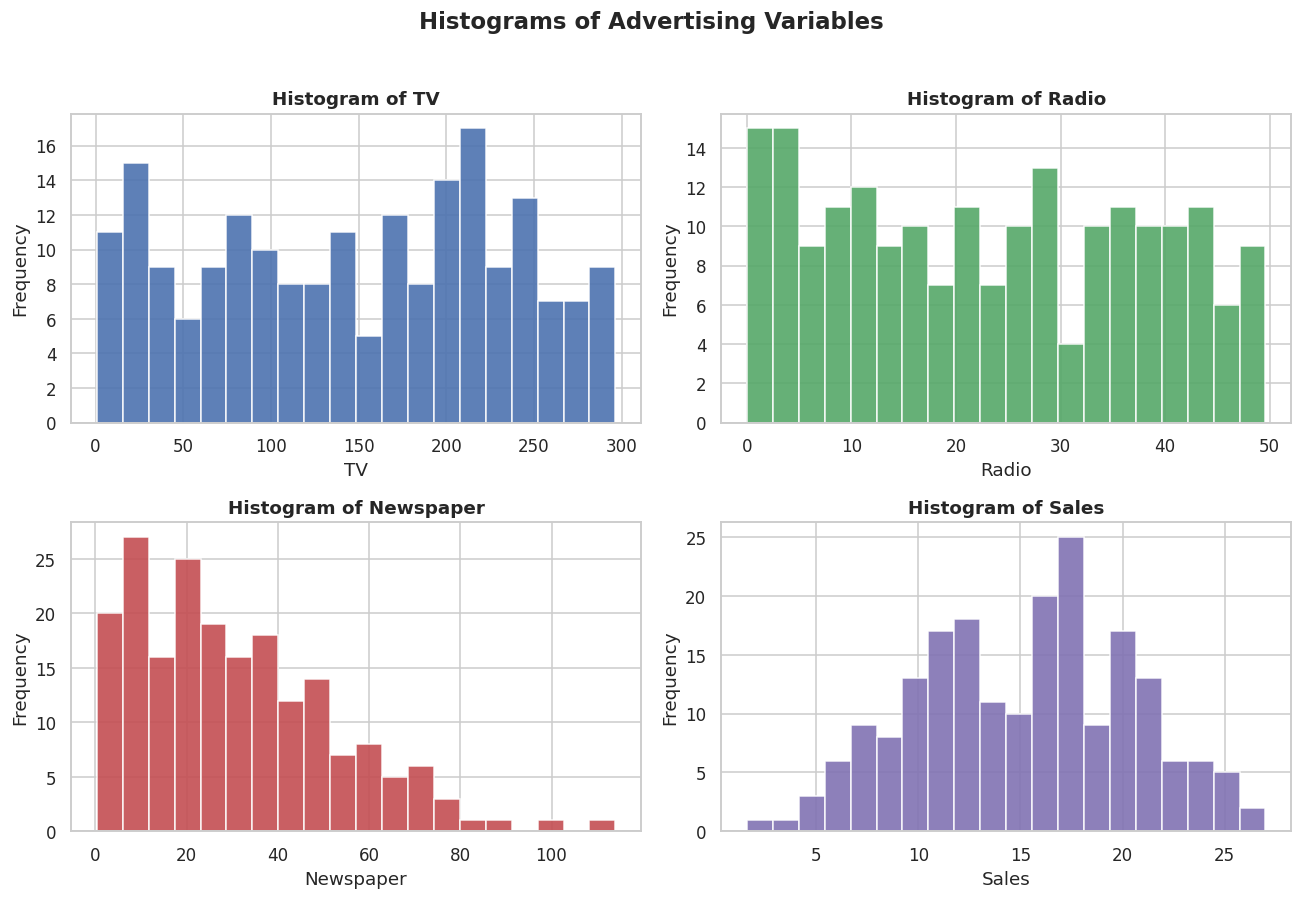

In [12]:
# Histograms of all four columns in a 2 x 2 grid
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B3"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col, color in zip(axes.ravel(), df.columns, colors):
    ax.hist(df[col], bins=20, color=color, edgecolor="white", alpha=0.9)
    ax.set_title(f"Histogram of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.suptitle("Histograms of Advertising Variables", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**📝 Interpretation**
- `TV` and `Radio` are spread **fairly evenly** across their ranges – the data covers both low and high budgets, which is excellent for learning.
- `Newspaper` is **right-skewed**: most markets spend little, and only a few spend a lot.
- `Sales` is **roughly bell-shaped**, centered around 15 – good news for regression models.

---

## 7.2 📈 Distribution Plots (KDE)
A **Kernel Density Estimate (KDE)** is a smooth version of a histogram. It makes skewness and multiple peaks easier to spot.

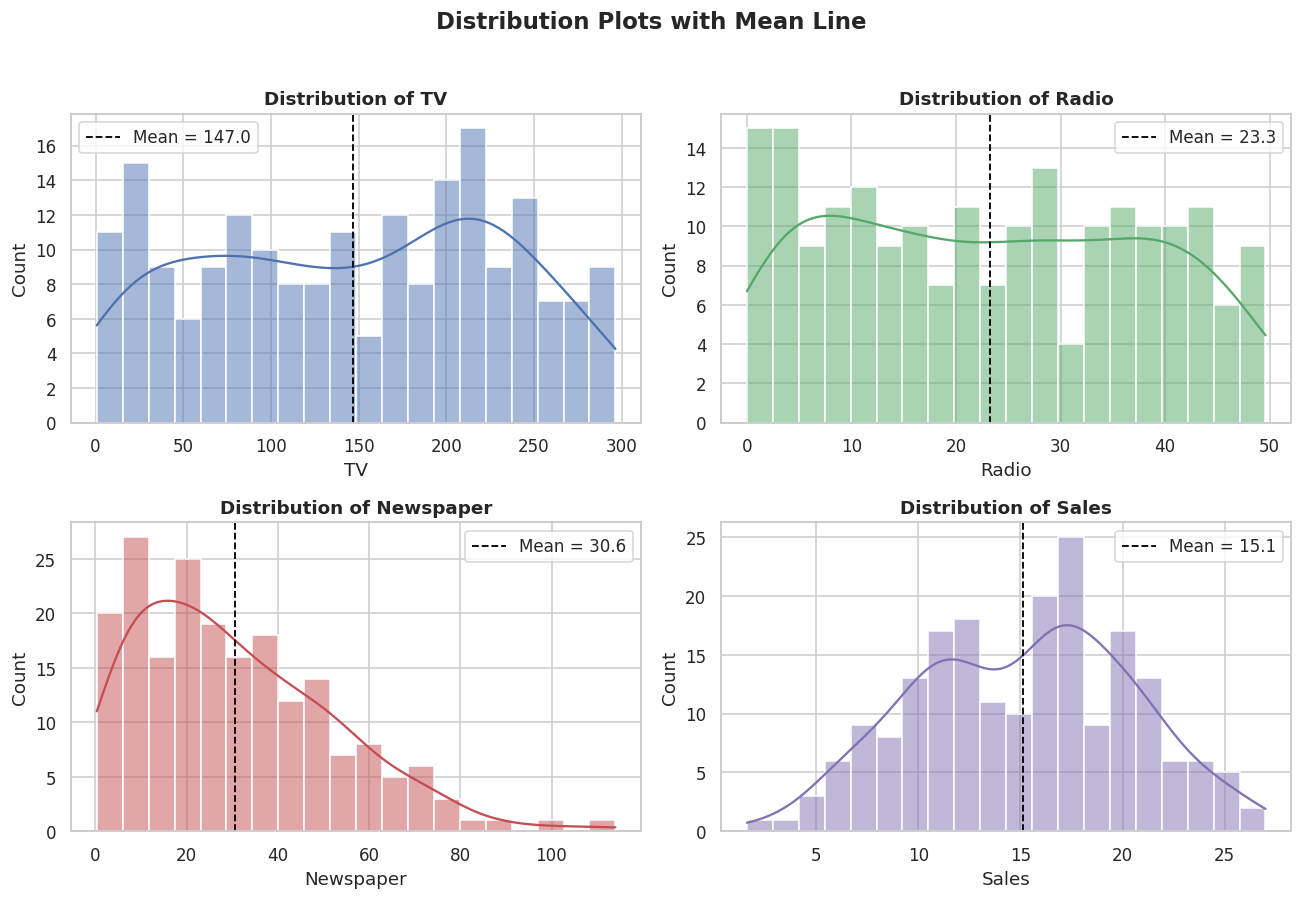

Skewness of each column:

TV          -0.07
Radio        0.09
Newspaper    0.89
Sales       -0.07
dtype: float64


In [13]:
# Distribution plots (histogram + smooth KDE curve) for each variable
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col, color in zip(axes.ravel(), df.columns, colors):
    sns.histplot(df[col], kde=True, bins=20, color=color, ax=ax)
    ax.axvline(df[col].mean(), color="black", linestyle="--", linewidth=1.2, label=f"Mean = {df[col].mean():.1f}")
    ax.set_title(f"Distribution of {col}")
    ax.legend()

plt.suptitle("Distribution Plots with Mean Line", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Skewness: 0 = symmetric, > 0.5 = noticeably right-skewed
print("Skewness of each column:\n")
print(df.skew().round(2))

**📝 Interpretation**
- `TV`, `Radio` and `Sales` have skewness close to **0** → nearly symmetric.
- `Newspaper` has clearly **positive skewness (~0.9)** → a long right tail of a few very high budgets.
- Tree-based models are not sensitive to skewness, and linear regression handles this level well, so **no transformation is required**.

---

## 7.3 📦 Box Plots
A box plot summarises a variable using the **median, quartiles and outliers**. The box covers the middle 50% of the data; points beyond the whiskers are potential outliers.

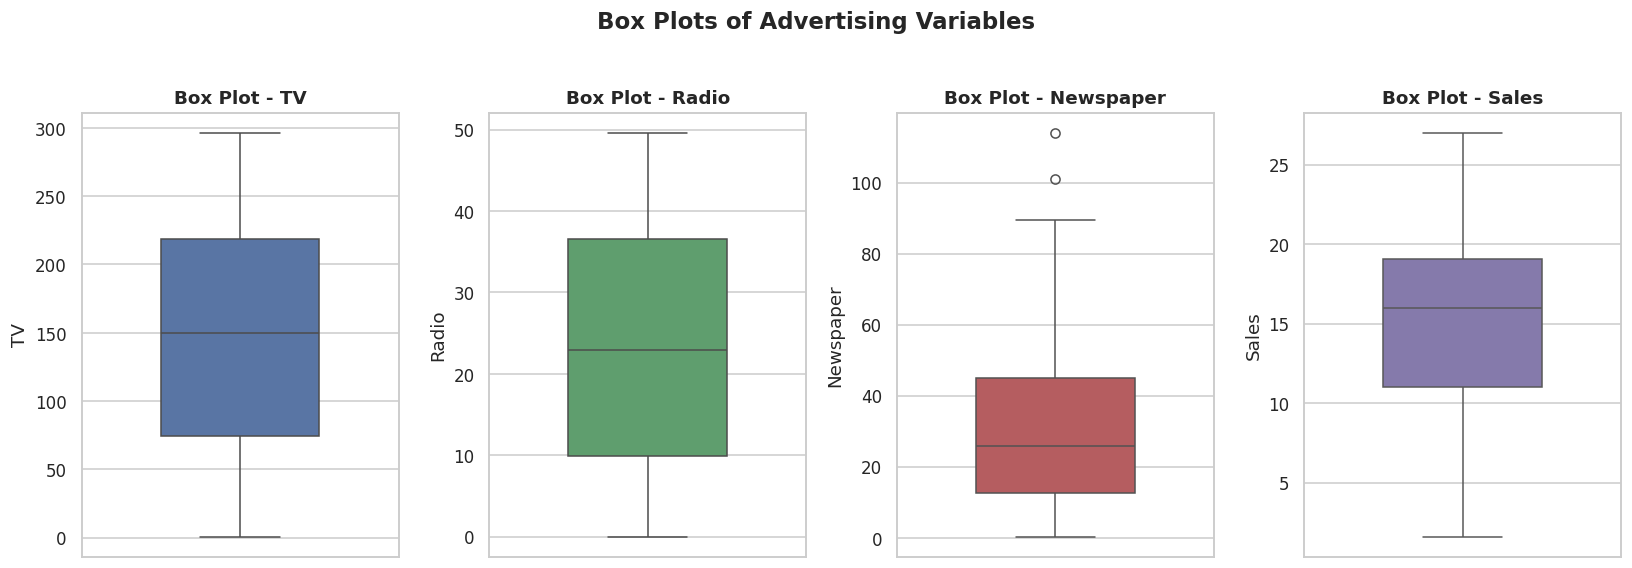

In [14]:
# Box plots - one per column, each on its own scale
fig, axes = plt.subplots(1, 4, figsize=(15, 5))

for ax, col, color in zip(axes, df.columns, colors):
    sns.boxplot(y=df[col], color=color, width=0.5, ax=ax)
    ax.set_title(f"Box Plot - {col}")

plt.suptitle("Box Plots of Advertising Variables", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**📝 Interpretation**
- `TV`, `Radio` and `Sales` show **no outliers** – their whiskers cover all data points.
- `Newspaper` shows **a couple of points above the upper whisker** (budgets near 100+). We investigate them in Section 7.10.

---

## 7.4 🔗 Pair Plot
A pair plot draws **every variable against every other variable**. The diagonal shows each variable's distribution and the red lines show the linear trend.

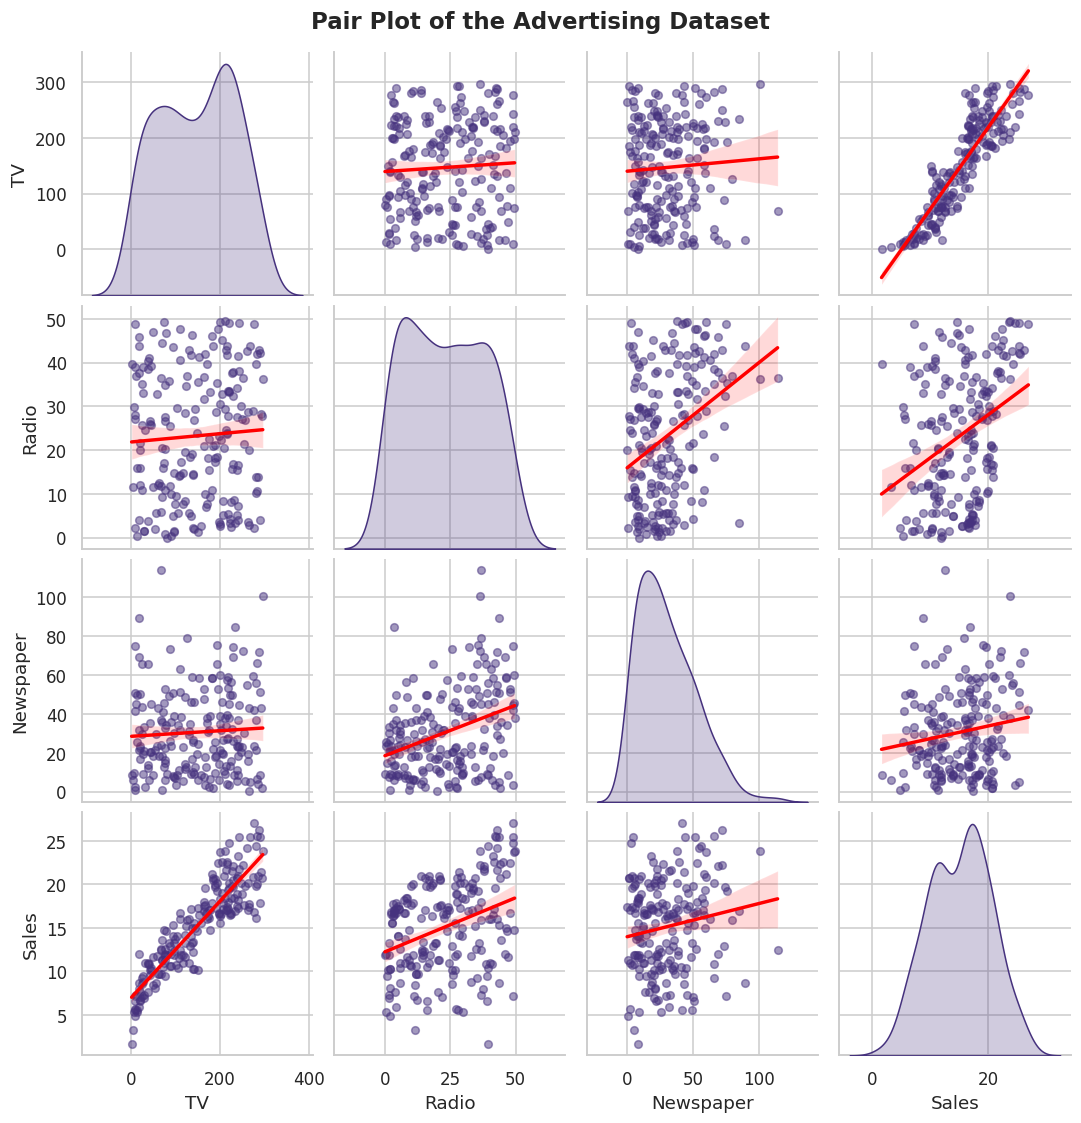

In [15]:
# Pair plot: scatter plots of all variable pairs with a regression line
pair_grid = sns.pairplot(
    df,
    kind="reg",
    diag_kind="kde",
    plot_kws={"line_kws": {"color": "red"}, "scatter_kws": {"alpha": 0.5, "s": 25}},
)
pair_grid.fig.suptitle("Pair Plot of the Advertising Dataset", y=1.02, fontsize=15, fontweight="bold")
plt.show()

**📝 Interpretation**
- The **TV vs Sales** panel shows a **tight, strongly upward trend** – TV spending and sales move together.
- **Radio vs Sales** shows a positive but **more scattered** trend.
- **Newspaper vs Sales** is almost a **cloud with a very weak slope** – little predictive power on its own.
- Advertising channels are not strongly related to each other, so each adds its own information.

---

## 7.5 🔥 Correlation Heatmap
The **Pearson correlation coefficient** ranges from **-1** (perfect negative) through **0** (no linear relationship) to **+1** (perfect positive). The heatmap shows all pairwise correlations at a glance.

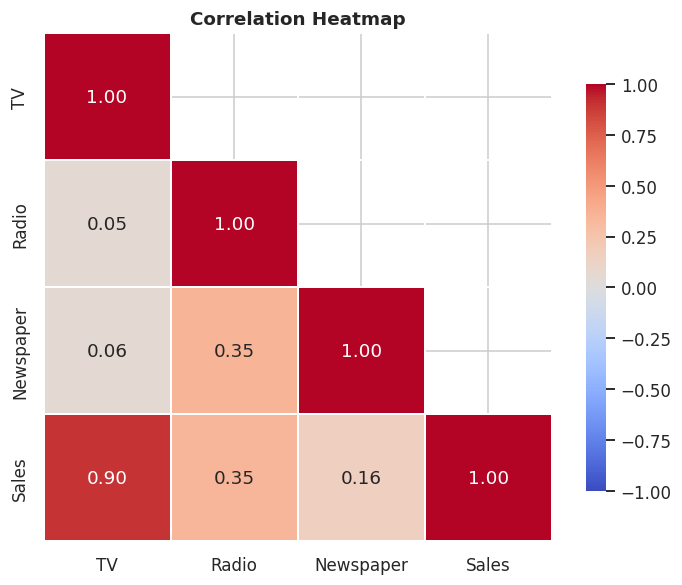

Correlation with Sales:

TV           0.901
Radio        0.350
Newspaper    0.158
Name: Sales, dtype: float64


In [16]:
# Correlation matrix and heatmap (lower triangle only to avoid duplicate information)
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", mask=mask,
            linewidths=1, linecolor="white", vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap")
plt.show()

# Correlation of every feature with the target, sorted from strongest to weakest
print("Correlation with Sales:\n")
print(corr["Sales"].drop("Sales").sort_values(ascending=False).round(3))

**📝 Interpretation**

| Feature | Correlation with Sales | Meaning |
|---------|-----------------------|---------|
| **TV** | ≈ **0.90** | 🔥 Very strong positive relationship |
| **Radio** | ≈ **0.35** | 🙂 Moderate positive relationship |
| **Newspaper** | ≈ **0.16** | 😐 Weak relationship |

TV is by far the strongest indicator of sales. Newspaper has only a weak link and we will see later that it contributes almost nothing to the model.

---

## 7.6 📺📻📰 Each Channel vs Sales
Individual scatter plots let us inspect **the shape of the relationship** for each advertising channel – linear, curved, or random.

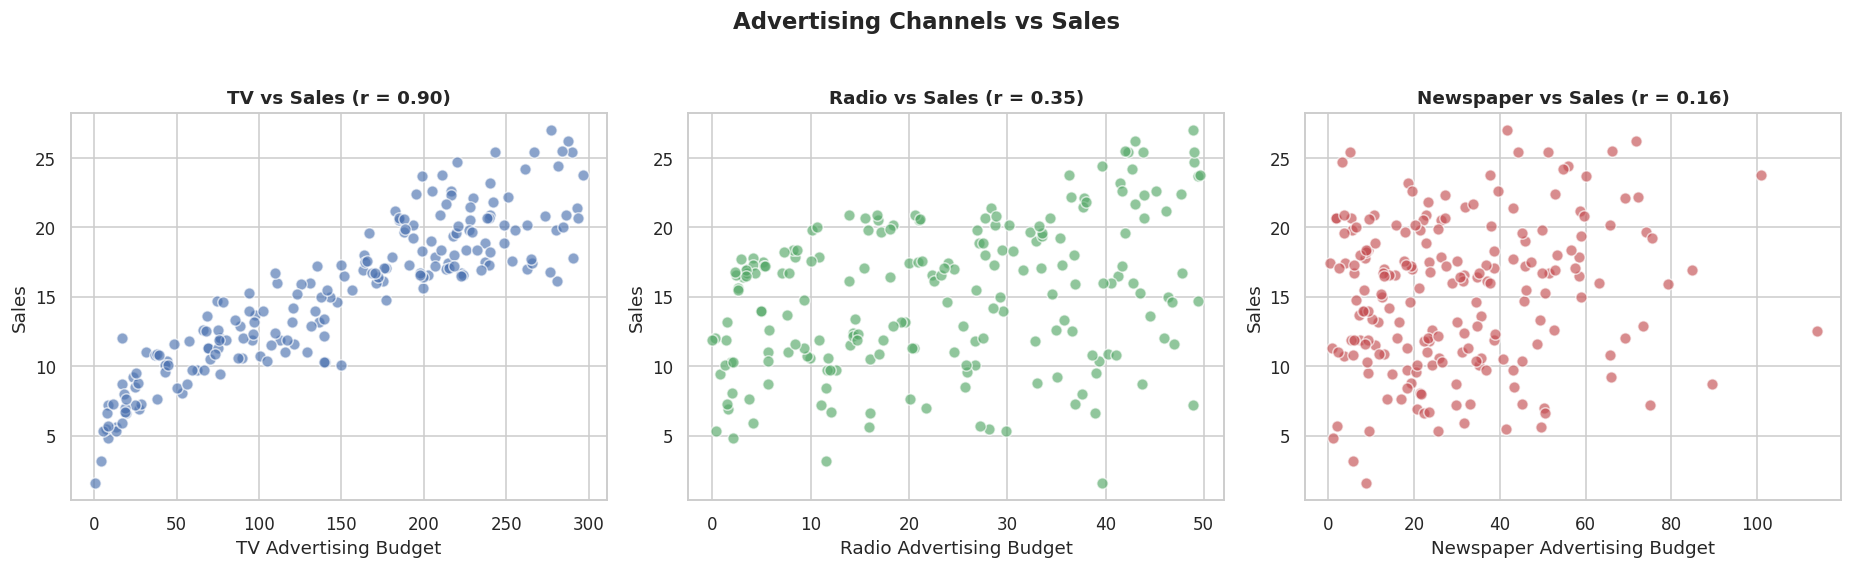

In [17]:
# Scatter plots: TV vs Sales, Radio vs Sales, Newspaper vs Sales
channels = [("TV", "#4C72B0", "📺"), ("Radio", "#55A868", "📻"), ("Newspaper", "#C44E52", "📰")]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (col, color, icon) in zip(axes, channels):
    ax.scatter(df[col], df["Sales"], color=color, alpha=0.65, edgecolor="white", s=55)
    ax.set_title(f"{col} vs Sales (r = {df[col].corr(df['Sales']):.2f})")
    ax.set_xlabel(f"{col} Advertising Budget")
    ax.set_ylabel("Sales")

plt.suptitle("Advertising Channels vs Sales", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**📝 Interpretation**
- **TV vs Sales:** a clear, almost linear increase – more TV spend means more sales. The spread widens slightly at high budgets.
- **Radio vs Sales:** an upward trend with larger variation – radio helps, but it is not the whole story.
- **Newspaper vs Sales:** points are scattered with no strong pattern – newspaper spend is a weak driver of sales.

---

## 7.7 🎯 Sales Distribution
Since `Sales` is our **target variable**, its distribution matters most. We check its centre, spread and shape.

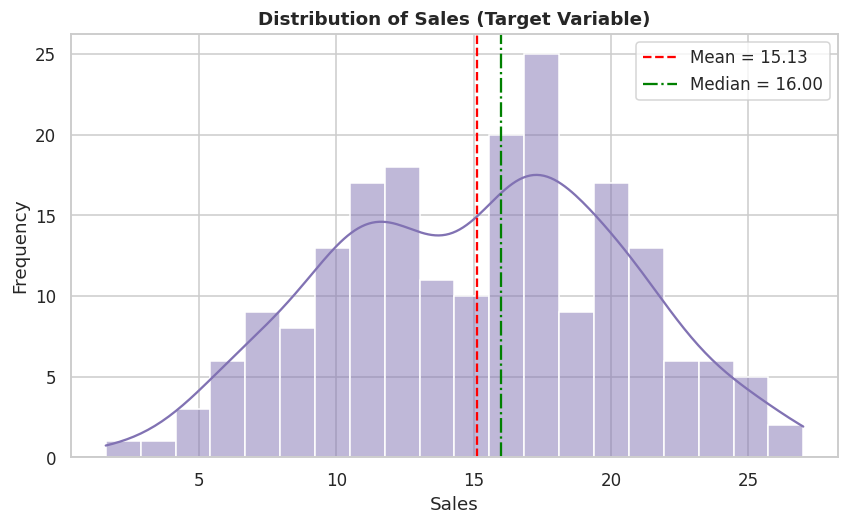

Min: 1.6 | Max: 27.0 | Std: 5.28


In [18]:
# Distribution of the target variable with mean and median lines
plt.figure(figsize=(9, 5))
sns.histplot(df["Sales"], kde=True, bins=20, color="#8172B3")
plt.axvline(df["Sales"].mean(), color="red", linestyle="--", label=f"Mean = {df['Sales'].mean():.2f}")
plt.axvline(df["Sales"].median(), color="green", linestyle="-.", label=f"Median = {df['Sales'].median():.2f}")
plt.title("Distribution of Sales (Target Variable)")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.legend()
plt.show()

print(f"Min: {df['Sales'].min()} | Max: {df['Sales'].max()} | Std: {df['Sales'].std():.2f}")

**📝 Interpretation**
- The mean and median are close (about 15 and 16), so the target is **approximately symmetric**.
- Most markets sell between **11 and 19 units** (the inter-quartile range).
- There are no extreme target outliers, so regression metrics such as RMSE will be meaningful.

---

## 7.8 📉 Regression Plots
`regplot` fits a **best-fit line with a 95% confidence band** for each feature. A narrow band means a reliable relationship; a wide band means uncertainty.

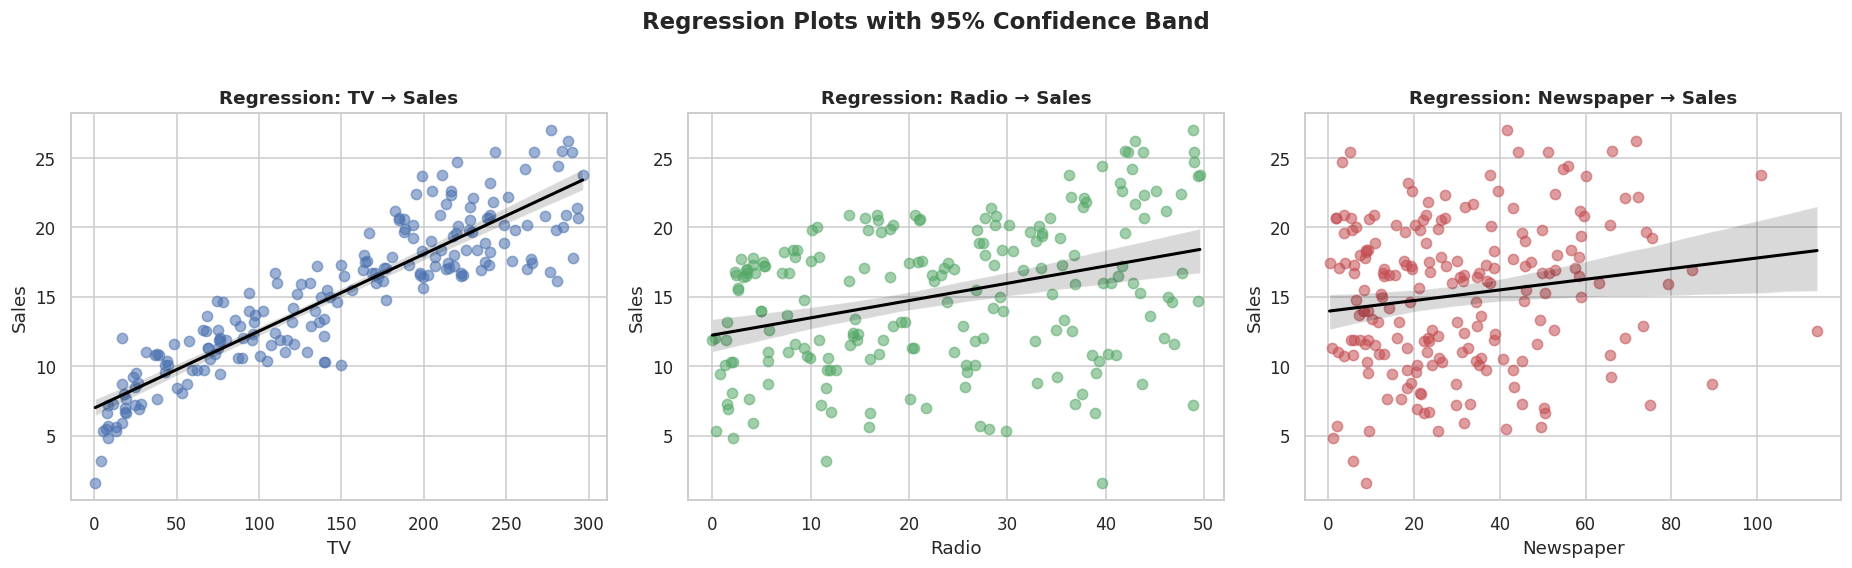

In [19]:
# Regression plots with confidence intervals
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (col, color, icon) in zip(axes, channels):
    sns.regplot(x=col, y="Sales", data=df, ax=ax,
                scatter_kws={"alpha": 0.55, "color": color, "s": 45},
                line_kws={"color": "black", "linewidth": 2})
    ax.set_title(f"Regression: {col} → Sales")

plt.suptitle("Regression Plots with 95% Confidence Band", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**📝 Interpretation**
- **TV:** steep line, narrow band → strong, dependable relationship.
- **Radio:** clearly positive slope, wider band → useful but less precise.
- **Newspaper:** almost flat line with a very wide band → practically no reliable effect.

---

## 7.9 🚨 Outlier Detection and Visualization
We use the **IQR (Inter-Quartile Range) rule**: a value is an outlier if it is below `Q1 − 1.5×IQR` or above `Q3 + 1.5×IQR`.

Outliers per column (IQR rule):

  TV         -> 0 outlier(s)   [valid range: -142.3 to 435.5]
  Radio      -> 0 outlier(s)   [valid range: -29.8 to 76.3]
  Newspaper  -> 2 outlier(s)   [valid range: -35.8 to 93.6]
  Sales      -> 0 outlier(s)   [valid range: -1.1 to 31.1]


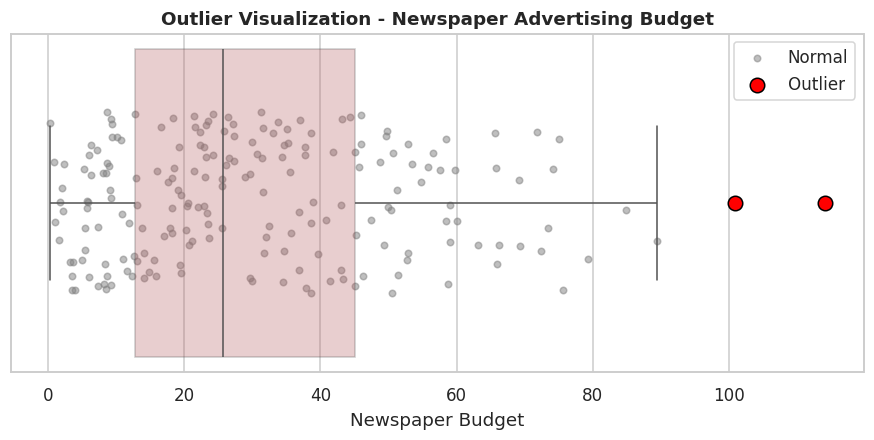


Rows flagged as Newspaper outliers:


,TV,Radio,Newspaper,Sales
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


In [20]:
# Detect outliers with the IQR rule for every column
outlier_summary = {}
bounds = {}

for col in df.columns:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    bounds[col] = (lower, upper)
    outlier_summary[col] = int(((df[col] < lower) | (df[col] > upper)).sum())

print("Outliers per column (IQR rule):\n")
for col, count in outlier_summary.items():
    print(f"  {col:<10} -> {count} outlier(s)   [valid range: {bounds[col][0]:.1f} to {bounds[col][1]:.1f}]")

# Visualize the Newspaper outliers: box plot + all points, outliers in red
lower, upper = bounds["Newspaper"]
is_outlier = (df["Newspaper"] < lower) | (df["Newspaper"] > upper)

plt.figure(figsize=(10, 4))
sns.boxplot(x=df["Newspaper"], color="#C44E52", width=0.5, fliersize=0, boxprops={"alpha": 0.3})
plt.scatter(df.loc[~is_outlier, "Newspaper"], np.random.RandomState(42).uniform(-0.15, 0.15, (~is_outlier).sum()),
            color="gray", alpha=0.5, s=18, label="Normal")
plt.scatter(df.loc[is_outlier, "Newspaper"], np.zeros(is_outlier.sum()),
            color="red", s=90, edgecolor="black", zorder=5, label="Outlier")
plt.title("Outlier Visualization - Newspaper Advertising Budget")
plt.xlabel("Newspaper Budget")
plt.legend()
plt.show()

print("\nRows flagged as Newspaper outliers:")
df[is_outlier]

**📝 Interpretation & Decision**
- Only **`Newspaper`** contains outliers – **2 markets** with unusually high newspaper budgets.
- They are **valid business observations** (a few markets simply invested heavily), not data-entry errors.
- With only 200 rows, deleting data would hurt more than help, and **tree-based models are robust to outliers**. We therefore **keep them**.

---

# 🎛️ 8. Feature Selection

| Role | Variables |
|------|-----------|
| 🔹 **Input features (X)** | `TV`, `Radio`, `Newspaper` |
| 🎯 **Target (y)** | `Sales` |

### 🤔 Why is `Sales` the target?
- **Business logic:** advertising is something a company *controls* (the cause); sales is the *outcome* it wants to influence (the effect). We predict the outcome from the controllable inputs.
- **Business value:** knowing expected sales for a given budget lets managers plan spending *before* committing money.
- **Data type:** `Sales` is a continuous number, which makes this a **regression** problem.

> All three advertising columns are kept as features. Newspaper has a weak correlation, but we let the models and the feature-importance analysis confirm its real contribution instead of dropping it by assumption.

In [21]:
# Separate inputs (X) from the target (y)
features = ["TV", "Radio", "Newspaper"]
target = "Sales"

X = df[features]   # independent variables (what we control)
y = df[target]     # dependent variable (what we want to predict)

print("Feature matrix X shape :", X.shape)
print("Target vector  y shape :", y.shape)
X.head()

Feature matrix X shape : (200, 3)
Target vector  y shape : (200,)


,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


# ✂️ 9. Train-Test Split

We divide the data into two parts:

| Set | Size | Purpose |
|-----|------|---------|
| 🏋️ **Training set** | **80%** (160 rows) | The model learns patterns from this data |
| 🧪 **Testing set** | **20%** (40 rows) | Unseen data used to measure real-world performance |

`random_state=42` guarantees **the same split every time**, so results are reproducible.

In [22]:
# 80% training / 20% testing, reproducible with random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training samples : {X_train.shape[0]}  ({X_train.shape[0] / len(df):.0%})")
print(f"Testing samples  : {X_test.shape[0]}  ({X_test.shape[0] / len(df):.0%})")

Training samples : 160  (80%)
Testing samples  : 40  (20%)


# 🤖 10. Build Machine Learning Models

We compare **three regression algorithms** of increasing complexity:

| Model | How it works | Strength | Weakness |
|-------|--------------|----------|----------|
| 📏 **Linear Regression** | Fits a straight line/plane: `Sales = b0 + b1·TV + b2·Radio + b3·Newspaper` | Simple, fast, interpretable | Cannot capture curved or interaction effects |
| 🌳 **Decision Tree** | Splits data into branches using if/else rules | Captures non-linear patterns | Can overfit and be unstable |
| 🌲 **Random Forest** | Averages many decision trees trained on random subsets | Accurate, robust, reduces overfitting | Less interpretable, slower |

In [23]:
# Model 1: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)      # learn from the training data

print("✅ Linear Regression trained")
print(f"   Intercept   : {lr_model.intercept_:.4f}")
for name, coef in zip(features, lr_model.coef_):
    print(f"   Coef [{name:<9}]: {coef:.4f}")

✅ Linear Regression trained
   Intercept   : 4.7141
   Coef [TV       ]: 0.0545
   Coef [Radio    ]: 0.1009
   Coef [Newspaper]: 0.0043


In [24]:
# Model 2: Decision Tree Regressor
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

print("✅ Decision Tree trained")
print(f"   Tree depth : {dt_model.get_depth()}   |   Leaves : {dt_model.get_n_leaves()}")

✅ Decision Tree trained
   Tree depth : 13   |   Leaves : 150


In [25]:
# Model 3: Random Forest Regressor (200 trees)
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

print("✅ Random Forest trained")
print(f"   Number of trees : {len(rf_model.estimators_)}")

✅ Random Forest trained
   Number of trees : 200


### 🧠 Reading the Linear Regression coefficients
Each coefficient says *"how much does Sales change if this budget increases by one unit, keeping the others fixed?"*

- **Radio** has the largest coefficient per unit – each extra radio unit has a high payoff.
- **TV** has a smaller coefficient per unit, but TV budgets are much larger, which is why it dominates overall.
- **Newspaper** has a coefficient **close to zero** – once TV and Radio are known, it adds almost nothing.

---

# 📏 11. Model Evaluation

We evaluate every model on the **test set** (data it has never seen) using four metrics.

| Metric | Formula (idea) | Meaning | Better when |
|--------|----------------|---------|-------------|
| **MAE** – Mean Absolute Error | average of &#124;actual − predicted&#124; | Typical error in the *same units as Sales*. Easy to explain. | ⬇️ Lower |
| **MSE** – Mean Squared Error | average of (actual − predicted)² | Penalises **large errors** more heavily. | ⬇️ Lower |
| **RMSE** – Root Mean Squared Error | √MSE | Error in the original units, but sensitive to big mistakes. | ⬇️ Lower |
| **R² Score** | 1 − (model error ÷ baseline error) | Share of variance in Sales the model explains. 1 = perfect, 0 = no better than predicting the mean. | ⬆️ Higher |

In [26]:
# Helper function: predict on the test set and compute all four metrics
def evaluate_model(model_name, model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    mae = mean_absolute_error(y_eval, y_pred)
    mse = mean_squared_error(y_eval, y_pred)
    rmse = np.sqrt(mse)                 # RMSE = square root of MSE
    r2 = r2_score(y_eval, y_pred)
    return {"Model": model_name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R² Score": r2}

# Keep all trained models in one dictionary so we can loop over them
models = {
    "Linear Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
}

# Evaluate every model on the unseen test data
results = [evaluate_model(name, model, X_test, y_test) for name, model in models.items()]

for r in results:
    print(f"{r['Model']:<18} | MAE: {r['MAE']:.4f} | MSE: {r['MSE']:.4f} | RMSE: {r['RMSE']:.4f} | R²: {r['R² Score']:.4f}")

Linear Regression  | MAE: 1.2748 | MSE: 2.9078 | RMSE: 1.7052 | R²: 0.9059
Decision Tree      | MAE: 1.2400 | MSE: 3.4020 | RMSE: 1.8445 | R²: 0.8899
Random Forest      | MAE: 0.9141 | MSE: 1.3991 | RMSE: 1.1828 | R²: 0.9547


### 🔁 Is the model overfitting?
A model that scores perfectly on training data but poorly on test data has **memorised** instead of **learned**. Comparing training R² with test R² reveals this.

In [27]:
# Compare train vs test R² for every model to detect overfitting
overfit_rows = []
for name, model in models.items():
    overfit_rows.append({
        "Model": name,
        "Train R²": r2_score(y_train, model.predict(X_train)),
        "Test R²": r2_score(y_test, model.predict(X_test)),
    })

overfit_df = pd.DataFrame(overfit_rows)
overfit_df["Gap (Train - Test)"] = overfit_df["Train R²"] - overfit_df["Test R²"]
overfit_df.round(4)

,Model,Train R²,Test R²,Gap (Train - Test)
0,Linear Regression,0.9001,0.9059,-0.0058
1,Decision Tree,1.0000,0.8899,0.1101
2,Random Forest,0.9918,0.9547,0.0370


**📝 Interpretation**
- **Decision Tree:** near-perfect training R² but a lower test R² → classic **overfitting** (it memorises the training rows).
- **Random Forest:** also very high on training data, but averaging 200 trees keeps the **test score high and stable**.
- **Linear Regression:** training and test scores are close → **stable and well-generalised**, but limited by its straight-line assumption.

---

# 🏆 12. Model Comparison

All models are placed in one table and ranked by **R² Score** (the main metric for regression quality).

In [28]:
# Build the comparison table, sorted from best to worst R²
results_df = pd.DataFrame(results).sort_values("R² Score", ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1          # rank starts at 1
results_df.index.name = "Rank"

# Colour-coded table: green = better for each metric
styled = (
    results_df.style
    .format({"MAE": "{:.4f}", "MSE": "{:.4f}", "RMSE": "{:.4f}", "R² Score": "{:.4f}"})
    .background_gradient(subset=["MAE", "MSE", "RMSE"], cmap="RdYlGn_r")   # lower = greener
    .background_gradient(subset=["R² Score"], cmap="RdYlGn")                # higher = greener
    .set_caption("🏆 Model Performance Comparison (Test Set)")
)
styled

,Model,MAE,MSE,RMSE,R² Score
Rank,,,,,
1,Random Forest,0.9141,1.3991,1.1828,0.9547
2,Linear Regression,1.2748,2.9078,1.7052,0.9059
3,Decision Tree,1.2400,3.4020,1.8445,0.8899


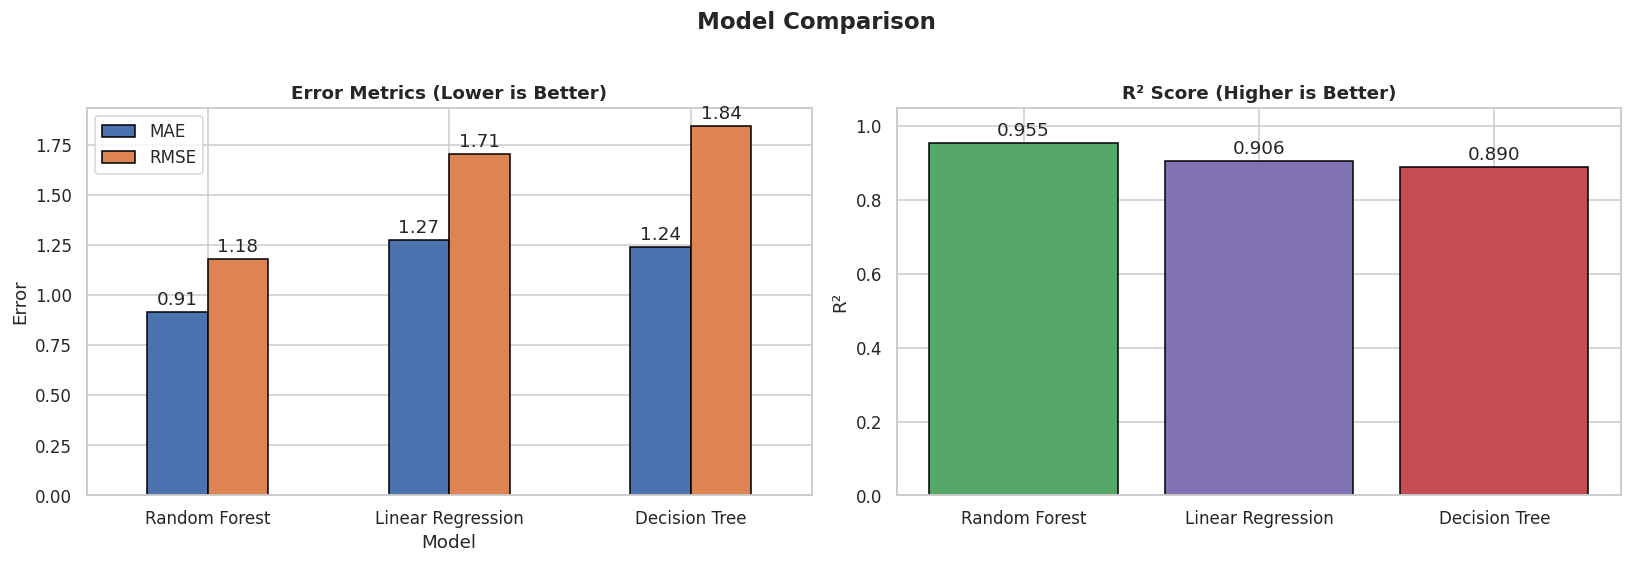

In [29]:
# Visual comparison: error metrics (lower is better) and R² (higher is better)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left chart: MAE and RMSE side by side
plot_df = results_df.set_index("Model")[["MAE", "RMSE"]]
plot_df.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"], edgecolor="black")
axes[0].set_title("Error Metrics (Lower is Better)")
axes[0].set_ylabel("Error")
axes[0].tick_params(axis="x", rotation=0)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", padding=2)

# Right chart: R² score
bars = axes[1].bar(results_df["Model"], results_df["R² Score"],
                   color=["#55A868", "#8172B3", "#C44E52"][:len(results_df)], edgecolor="black")
axes[1].set_title("R² Score (Higher is Better)")
axes[1].set_ylabel("R²")
axes[1].set_ylim(0, 1.05)
axes[1].bar_label(bars, fmt="%.3f", padding=2)

plt.suptitle("Model Comparison", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [30]:
# Automatically pick the best model (highest R² on the test set)
best_model_name = results_df.loc[1, "Model"]
best_model = models[best_model_name]
best_row = results_df.loc[1]

print(f"🏆 Best model : {best_model_name}")
print(f"   R² Score   : {best_row['R² Score']:.4f}  ->  explains {best_row['R² Score']:.1%} of the variation in Sales")
print(f"   MAE        : {best_row['MAE']:.4f}  ->  predictions are off by about {best_row['MAE'] * 1000:,.0f} units on average")
print(f"   RMSE       : {best_row['RMSE']:.4f}")

🏆 Best model : Random Forest
   R² Score   : 0.9547  ->  explains 95.5% of the variation in Sales
   MAE        : 0.9141  ->  predictions are off by about 914 units on average
   RMSE       : 1.1828


### 🥇 Which model performed best?

**Random Forest** gives the **highest R² (≈ 0.95)** and the **lowest MAE, MSE and RMSE** of the three models.

| Rank | Model | Verdict |
|------|-------|---------|
| 🥇 | **Random Forest** | Best accuracy – captures non-linear effects and the interaction between TV and Radio |
| 🥈 | **Linear Regression** | Strong baseline (R² ≈ 0.91) – simple, stable and easy to explain to managers |
| 🥉 | **Decision Tree** | Weakest – a single tree overfits the small training set |

**Why Random Forest wins:** the relationship between ad spend and sales is not perfectly linear, and channels can reinforce each other. A forest of trees models this flexibly while averaging out the noise of individual trees.

> 📌 *The best model is selected automatically by the code above, so the notebook stays correct even if the data changes.*

---

# 🌟 13. Feature Importance

A Random Forest can tell us **how much each feature contributed to its predictions**. The importances add up to 1 (100%). This turns a "black box" into a **business insight**.

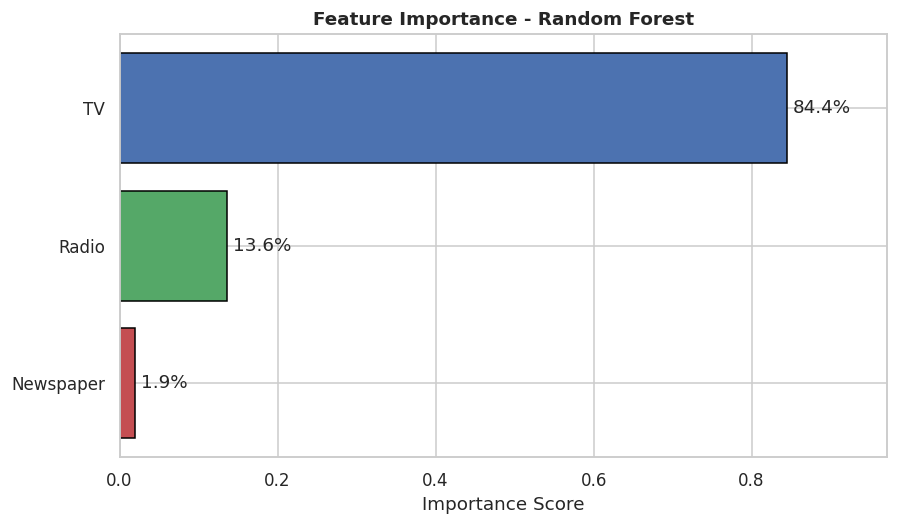

,Feature,Importance
0,TV,0.8444
1,Radio,0.1364
2,Newspaper,0.0192


In [31]:
# Extract feature importance from the Random Forest
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_,
}).sort_values("Importance", ascending=True)       # ascending so the biggest bar is on top

# Horizontal bar chart
plt.figure(figsize=(9, 5))
bars = plt.barh(importance_df["Feature"], importance_df["Importance"],
                color=["#C44E52", "#55A868", "#4C72B0"], edgecolor="black")
plt.bar_label(bars, labels=[f"{v:.1%}" for v in importance_df["Importance"]], padding=4)
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.xlim(0, importance_df["Importance"].max() * 1.15)
plt.show()

importance_df.sort_values("Importance", ascending=False).reset_index(drop=True).round(4)

### 💡 Business Insights

1. 📺 **TV is the dominant driver (~84%)** – it is the single most important lever for sales. Protect and prioritise the TV budget.
2. 📻 **Radio is a valuable secondary channel (~14%)** – a smart complement to TV, especially because it needs a much smaller budget.
3. 📰 **Newspaper contributes almost nothing (~2%)** – shifting newspaper money into TV or Radio is likely to deliver a better return.

> 🎯 **Recommendation:** Focus the budget on **TV + Radio** and review newspaper spending. Always validate with a controlled campaign test, because correlation does not prove causation.

---

# 🔍 14. Actual vs Predicted

If a model were perfect, every point would lie exactly on the **diagonal line** (predicted = actual). The closer the points are to that line, the better the model.

We analyse the **best model** selected in Section 12.

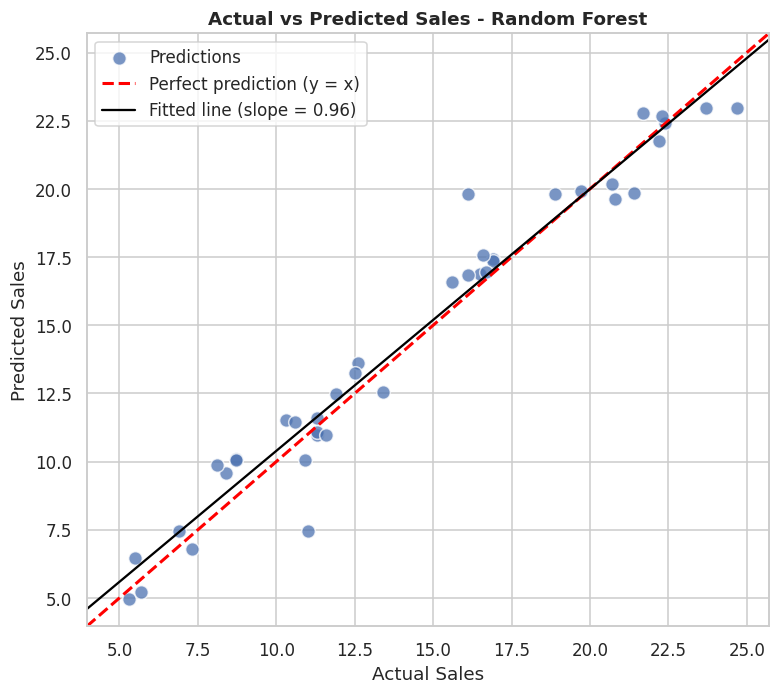

In [32]:
# Predictions of the best model on the unseen test set
y_pred_best = best_model.predict(X_test)

# Scatter plot of actual vs predicted values
plt.figure(figsize=(8, 7))
plt.scatter(y_test, y_pred_best, color="#4C72B0", alpha=0.75, edgecolor="white", s=80, label="Predictions")

# Perfect-prediction reference line (y = x)
lims = [min(y_test.min(), y_pred_best.min()) - 1, max(y_test.max(), y_pred_best.max()) + 1]
plt.plot(lims, lims, color="red", linestyle="--", linewidth=2, label="Perfect prediction (y = x)")

# Fitted regression line through the predictions
slope, intercept = np.polyfit(y_test, y_pred_best, 1)
plt.plot(lims, [slope * v + intercept for v in lims], color="black", linewidth=1.5, label=f"Fitted line (slope = {slope:.2f})")

plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title(f"Actual vs Predicted Sales - {best_model_name}")
plt.legend()
plt.show()

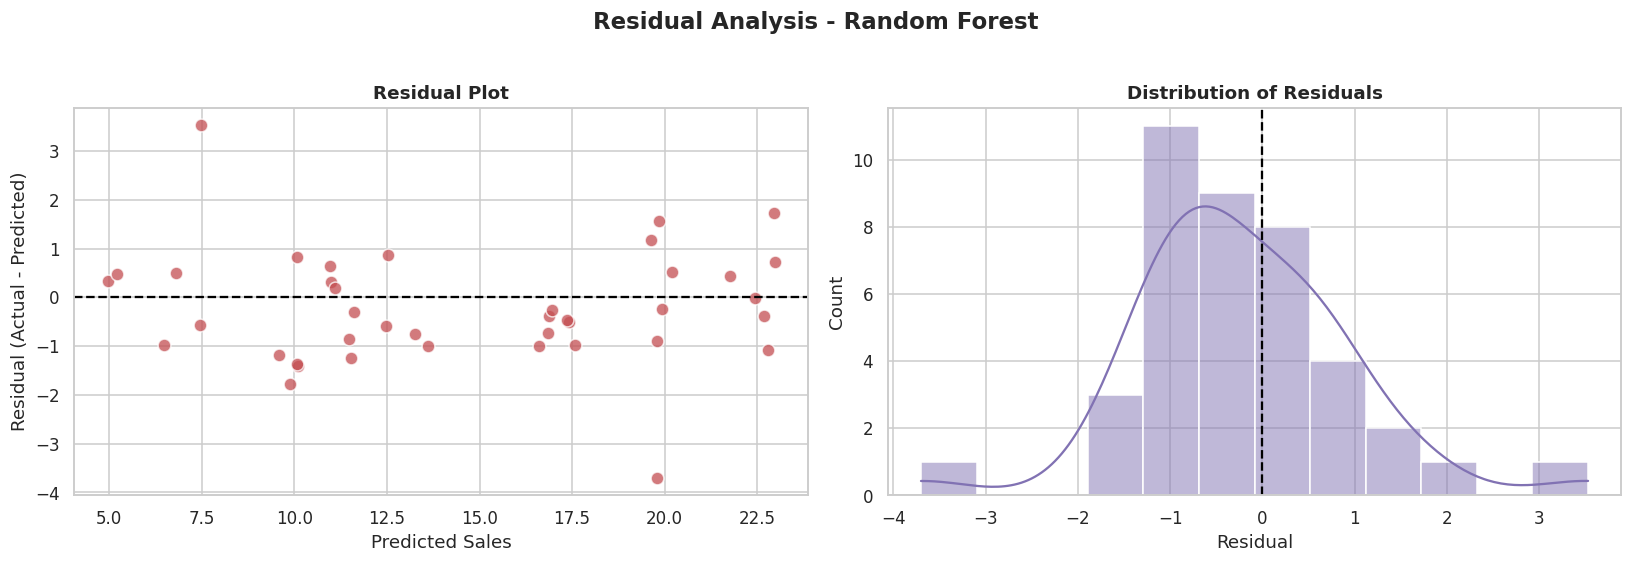

Mean residual     : -0.2209  (close to 0 = no systematic bias)
Residual std dev  : 1.1768
Largest over-prediction  : -3.70
Largest under-prediction : 3.53


In [33]:
# Residual analysis: residual = actual - predicted
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: residuals vs predicted values (should look like a random cloud around 0)
axes[0].scatter(y_pred_best, residuals, color="#C44E52", alpha=0.75, edgecolor="white", s=70)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1.5)
axes[0].set_title("Residual Plot")
axes[0].set_xlabel("Predicted Sales")
axes[0].set_ylabel("Residual (Actual - Predicted)")

# Right: distribution of residuals (should be centred near 0 and bell-shaped)
sns.histplot(residuals, kde=True, bins=12, color="#8172B3", ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", linewidth=1.5)
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual")

plt.suptitle(f"Residual Analysis - {best_model_name}", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"Mean residual     : {residuals.mean():.4f}  (close to 0 = no systematic bias)")
print(f"Residual std dev  : {residuals.std():.4f}")
print(f"Largest over-prediction  : {residuals.min():.2f}")
print(f"Largest under-prediction : {residuals.max():.2f}")

### 🧠 Model Behaviour

- **Actual vs Predicted:** points hug the red diagonal, which confirms strong agreement between predicted and real sales.
- **Residual plot:** residuals scatter **randomly around zero** with no obvious curve or funnel, so there is no major systematic error.
- **Residual distribution:** centred near **0** and roughly bell-shaped → errors are mostly small and unbiased.
- **Weak spots:** a few points sit further from the line (notably at the extremes), where data is thinner. More data or tuning could reduce these errors.

---

# 🔮 15. Predict New Sales

Let's use the trained model in a realistic **business scenario**.

| Channel | Planned Budget |
|---------|---------------|
| 📺 TV | **230** |
| 📻 Radio | **37** |
| 📰 Newspaper | **69** |

> Budgets are in thousands of dollars, sales are in thousands of units – the same units as the training data.

In [34]:
# Create the new advertising plan as a DataFrame with the SAME column names used in training
new_plan = pd.DataFrame({"TV": [230], "Radio": [37], "Newspaper": [69]})

# Predict with the best model
predicted_sales = best_model.predict(new_plan)[0]

print("📋 New advertising plan:")
print(new_plan.to_string(index=False))
print(f"\n🔮 Predicted Sales ({best_model_name}): {predicted_sales:.2f}  (≈ {predicted_sales * 1000:,.0f} units)")

# For comparison, show what every model predicts for the same plan
print("\n📊 Predictions from all models:")
for name, model in models.items():
    print(f"   {name:<18}: {model.predict(new_plan)[0]:.2f}")

📋 New advertising plan:
 TV  Radio  Newspaper
230     37         69

🔮 Predicted Sales (Random Forest): 21.81  (≈ 21,811 units)

📊 Predictions from all models:
   Linear Regression : 21.29
   Decision Tree     : 22.10
   Random Forest     : 21.81


### 🧠 Explaining the Prediction

- The plan has a **high TV budget (230)** and a **solid Radio budget (37)** – the two channels the model trusts most.
- The model predicts sales of roughly **21.8 thousand units (about 21,800 units)**, which sits in the **upper range** of the dataset (maximum ≈ 27, average ≈ 15).
- The **Newspaper budget (69)** is well above average, but the model gives it very little weight, so it barely affects the result.
- All three models predict values within a narrow band (roughly 21–22), which gives extra **confidence** in the forecast.

> 💼 **Business takeaway:** this plan is expected to deliver well above-average sales, and reducing the newspaper spend would likely lower cost without hurting results.

---

# 💾 16. Save the Best Model

Training takes time; **saving** the model lets us reuse it instantly – in a web app, an API or another notebook – **without retraining**.

We use `joblib.dump()`, which is efficient for scikit-learn models, and save the file as **`sales_prediction_model.pkl`**.

In [35]:
# Save the best model to disk
MODEL_FILE = "sales_prediction_model.pkl"
joblib.dump(best_model, MODEL_FILE)

size_kb = os.path.getsize(MODEL_FILE) / 1024
print(f"💾 Model saved as '{MODEL_FILE}'  ({size_kb:.1f} KB)")

# Reload it and verify it gives the exact same prediction
loaded_model = joblib.load(MODEL_FILE)
reloaded_prediction = loaded_model.predict(new_plan)[0]

print(f"🔄 Prediction from reloaded model : {reloaded_prediction:.2f}")
print(f"✅ Identical to original prediction: {np.isclose(reloaded_prediction, predicted_sales)}")

# In Google Colab, also download the file to your computer
try:
    from google.colab import files
    files.download(MODEL_FILE)
except Exception:
    print("ℹ️ Not running in Colab - the file is saved in the current folder.")

💾 Model saved as 'sales_prediction_model.pkl'  (2752.0 KB)
🔄 Prediction from reloaded model : 21.81
✅ Identical to original prediction: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# ✅ 17. Conclusion

In this project I built a complete **Sales Prediction** pipeline with Python and scikit-learn.

### 🔑 Key Findings
- 🧹 The dataset was **clean**: 200 rows, no missing values, no duplicates.
- 📺 **TV advertising has the strongest relationship with sales** (correlation ≈ 0.90).
- 📻 Radio is a useful secondary driver; 📰 **Newspaper adds very little**.
- 🏆 **Random Forest was the best model** with **R² ≈ 0.95**, beating Linear Regression (R² ≈ 0.91) and Decision Tree (R² ≈ 0.89).
- 🔮 For the plan TV = 230, Radio = 37, Newspaper = 69, the model predicts about **21.8 thousand units**.
- 💾 The final model is saved as `sales_prediction_model.pkl` and ready for deployment.

### 💼 Business Value
Marketing teams can use this model to **forecast sales before spending**, move budget towards high-impact channels and **reduce wasted advertising money**.

### ⚠️ Limitations
- Small dataset (200 rows) – results may change with more data.
- Only three input features; real sales are also influenced by price, season, competition and more.
- The models were not hyperparameter-tuned, and the results come from a single train/test split.
- The model shows *association*, not proven *causation*.

# 🚀 18. Future Improvements

| Idea | Description |
|------|-------------|
| ⚡ **XGBoost** | Gradient boosting often beats Random Forest on tabular data |
| 💡 **LightGBM** | Fast, memory-efficient boosting, great for larger datasets |
| 🎛️ **Hyperparameter Tuning** | `GridSearchCV` / `RandomizedSearchCV` / Optuna to tune depth, number of trees, etc. |
| 🔁 **Cross Validation** | K-fold CV for a more reliable estimate than a single split |
| 🧪 **Feature Engineering** | Interaction terms (e.g. `TV × Radio`), total ad spend, log or polynomial features |
| 🖥️ **Streamlit App** | An interactive web dashboard where managers enter budgets and see predictions |
| 🌐 **Flask / FastAPI API** | Serve the model as a REST endpoint for other applications |
| ☁️ **Cloud Deployment** | Deploy on Render, Hugging Face Spaces, AWS, GCP or Azure |
| 📈 **Monitoring** | Track model drift and retrain when new sales data arrives |

# 🐙 19. GitHub Section (README.md)

Copy the content below into a file named **`README.md`** in the root of your GitHub repository.

````markdown
<div align="center">

# 📈 Sales Prediction using Python

**Predicting product sales from TV, Radio and Newspaper advertising budgets using Machine Learning**

![Python](https://img.shields.io/badge/Python-3.10+-blue?logo=python&logoColor=white)
![scikit-learn](https://img.shields.io/badge/scikit--learn-ML-orange?logo=scikit-learn&logoColor=white)
![Colab](https://img.shields.io/badge/Google%20Colab-Ready-F9AB00?logo=googlecolab&logoColor=white)
![License](https://img.shields.io/badge/License-MIT-green)

*CodeAlpha Data Science Internship – Task 4*

</div>

---

## 📌 Overview
This project predicts **Sales** based on advertising spend on **TV**, **Radio** and **Newspaper**.
It covers the full data-science workflow: data cleaning, EDA, model training, evaluation,
feature-importance analysis, prediction and model saving.

## 🎯 Objectives
- Understand how each advertising channel affects sales
- Compare Linear Regression, Decision Tree and Random Forest models
- Identify the most influential advertising channel
- Predict sales for new advertising budgets
- Save the best model for deployment

## 📂 Dataset
| Column | Description |
|--------|-------------|
| `TV` | TV advertising budget |
| `Radio` | Radio advertising budget |
| `Newspaper` | Newspaper advertising budget |
| `Sales` | Units sold (target) |

200 rows · 4 columns · no missing values · no duplicates

## 🛠️ Tech Stack
Python · Pandas · NumPy · Matplotlib · Seaborn · scikit-learn · Joblib

## 🔬 Methodology
1. Data loading and inspection
2. Data cleaning (missing values, duplicates, data types)
3. Exploratory data analysis (histograms, box plots, pair plot, heatmap, regression plots)
4. Train-test split (80/20, `random_state=42`)
5. Model training: Linear Regression, Decision Tree, Random Forest
6. Evaluation with MAE, MSE, RMSE and R²
7. Feature importance and residual analysis
8. Prediction on a new advertising plan and model export with `joblib`

## 🏆 Results
| Model | MAE | RMSE | R² |
|-------|-----|------|----|
| **Random Forest** | **0.91** | **1.18** | **0.955** |
| Linear Regression | 1.27 | 1.71 | 0.906 |
| Decision Tree | 1.24 | 1.84 | 0.890 |

**Key insight:** TV is the most influential channel (~84% importance), followed by Radio (~14%).
Newspaper contributes very little (~2%).

## ▶️ How to Run
**Google Colab (recommended)**
1. Open `notebooks/Sales_Prediction.ipynb` in Google Colab
2. Run *Runtime ▸ Run all*
3. Upload `Advertising.csv` when prompted

**Locally**
```bash
git clone https://github.com/<your-username>/sales-prediction-using-python.git
cd sales-prediction-using-python
pip install -r requirements.txt
jupyter notebook notebooks/Sales_Prediction.ipynb
```

## 🔮 Example Prediction
```python
import joblib, pandas as pd

model = joblib.load("models/sales_prediction_model.pkl")
new_plan = pd.DataFrame({"TV": [230], "Radio": [37], "Newspaper": [69]})
print(model.predict(new_plan))   # ≈ 21.8
```

## 🚀 Future Work
XGBoost · LightGBM · Hyperparameter tuning · Cross-validation · Feature engineering ·
Streamlit app · Flask/FastAPI API · Cloud deployment

## 👩‍💻 Author
**Prarthona Biswas Puja** – Software Engineering Student
CodeAlpha Data Science Intern

## 📜 License
This project is licensed under the MIT License.
````

# 📦 20. requirements.txt

Save the following as **`requirements.txt`** in the project root:

```text
pandas>=1.5.0
numpy>=1.23.0
matplotlib>=3.6.0
seaborn>=0.12.0
scikit-learn>=1.2.0
joblib>=1.2.0
jupyter>=1.0.0
```

The next cell generates this file automatically so you can download it.

In [36]:
# Write requirements.txt to disk (bonus: ready to upload to GitHub)
requirements = '''pandas>=1.5.0
numpy>=1.23.0
matplotlib>=3.6.0
seaborn>=0.12.0
scikit-learn>=1.2.0
joblib>=1.2.0
jupyter>=1.0.0
'''

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("✅ requirements.txt created:\n")
print(requirements)

# In Google Colab, download the file as well
try:
    from google.colab import files
    files.download("requirements.txt")
except Exception:
    pass

✅ requirements.txt created:

pandas>=1.5.0
numpy>=1.23.0
matplotlib>=3.6.0
seaborn>=0.12.0
scikit-learn>=1.2.0
joblib>=1.2.0
jupyter>=1.0.0



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 🗂️ 21. Project Folder Structure

A clean structure makes a project easy to navigate for recruiters and collaborators.

```text
sales-prediction-using-python/
│
├── 📁 data/
│   └── Advertising.csv                 # Raw dataset
│
├── 📁 notebooks/
│   └── Sales_Prediction.ipynb          # This notebook (full analysis)
│
├── 📁 models/
│   └── sales_prediction_model.pkl      # Saved best model (Random Forest)
│
├── 📁 images/                          # Exported charts for the README
│   ├── correlation_heatmap.png
│   ├── feature_importance.png
│   └── actual_vs_predicted.png
│
├── 📁 app/                             # (Future) Streamlit / Flask app
│   └── app.py
│
├── 📄 requirements.txt                 # Python dependencies
├── 📄 README.md                        # Project documentation
├── 📄 .gitignore                       # Files Git should ignore
└── 📄 LICENSE                          # MIT License
```

# 🌱 22. Best Practices Followed

| ✅ Practice | How it was applied |
|------------|--------------------|
| **Reproducibility** | `random_state=42` in the split and all models |
| **Clean workflow** | Load → Clean → Explore → Model → Evaluate → Save |
| **Unseen test data** | All metrics computed on the 20% held-out test set |
| **Multiple models** | A simple baseline compared with more advanced models |
| **Overfitting check** | Train vs test R² compared |
| **Interpretability** | Feature importance and coefficient analysis |
| **Model persistence** | Saved with `joblib` and verified by reloading |
| **Documentation** | Markdown explanation + comments for every step |
| **Colab-ready** | Automatic file detection and upload prompt |

---

<div align="center">

### 🙏 Thank You!

**Prarthona Biswas Puja** · Software Engineering Student
CodeAlpha Data Science Internship – Task 4: *Sales Prediction using Python*

⭐ *If you found this project useful, please consider giving it a star on GitHub!* ⭐

</div>